# Polynomial Regression Project: Predicting Car Fuel Efficiency (MPG)

**Goal:** predict how many **miles per gallon (mpg)** a car can drive, mainly from its **engine horsepower**.

**Why polynomial regression?** More horsepower means lower mpg, but **not in a straight line**: mpg drops fast at first and then levels off. A curve fits this much better than a straight line.

**Type of problem:** supervised learning → **regression** (mpg is a number).

**Dataset:** `auto_mpg.csv` (398 cars from the 1970s–80s), stored in this folder. Source: UCI Auto MPG dataset (copy from the seaborn-data repository).

| Column | Meaning |
|---|---|
| **mpg** | **Target:** miles per gallon (higher = more fuel efficient) |
| horsepower | Engine power |
| weight | Car weight (in pounds) |
| cylinders, displacement, acceleration, model_year, origin, name | Other details (not used in the main model) |

### Steps
1. Import libraries
2. Load and check the data
3. Clean the data
4. Look at the relationship (scatter plot)
5. Choose X and y, then train/test split
6. Baseline: a straight line (Linear Regression)
7. What PolynomialFeatures does
8. Polynomial Regression (degree 2)
9. Compare degrees 1 to 10
10. See underfitting and overfitting on a chart
11. Choose the best degree with cross-validation
12. Final model and evaluation
13. Bonus: two features (horsepower + weight)
14. Predict for a new car
15. Save the model
16. Conclusion

> **How to read the code:** lines starting with `#` are comments, notes for humans that Python ignores. Run the cells from top to bottom with **Shift + Enter**.

## 1. Import libraries


In [1]:
# 'import' opens a toolbox (library) so we can use its tools. "as pd" gives it a short nickname

import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 

# From scikit-learn (the machine learning toolbox) we take:

from sklearn.model_selection import train_test_split, cross_val_score, KFold  # splitting data and cross-validation
from sklearn.preprocessing import PolynomialFeatures, StandardScaler         # create x², x³ ... and scale numbers
from sklearn.linear_model import LinearRegression                            # the regression model
from sklearn.pipeline import make_pipeline                                   # join several steps into one model
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score  # ways to score the model
import joblib                                                                # to save the model to a file

## 2. load and check the data


In [4]:
# Read the csv file into a table
df = pd.read_csv("D:/AJAY_PYTHON/Python/ML/data/auto_mpg.csv")

# show the first 5 rows
df.head(5)

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [6]:
# Size of the table:(rows, columns)
print("Shape:",df.shape)

# Count empty (missing ) cells in each column
print("\n Missing Values: ")
print(df.isnull().sum())

# Count rows that are exact copies of another row
print("\n Duplicate rows:", df.duplicated().sum())


Shape: (398, 9)

 Missing Values: 
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64

 Duplicate rows: 0


## 3. Clean the data


In [7]:
# Remove the rows where horsepower is missing (only 6 out of 398 cars, so we lose very little).
df = df.dropna(subset=["horsepower"])

print("Shape after cleaning: ", df.shape)

# Basic statistics for the two columns we care about most

df[["horsepower", "mpg"]].describe().round(1)


Shape after cleaning:  (392, 9)


,horsepower,mpg
count,392.0,392.0
mean,104.5,23.4
std,38.5,7.8
min,46.0,9.0
25%,75.0,17.0
50%,93.5,22.8
75%,126.0,29.0
max,230.0,46.6


## 4. Look at the relationship

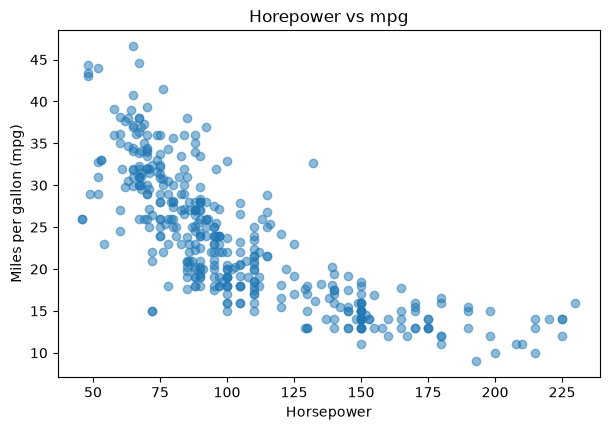

In [9]:
# Scatter plot : each dot is one car. Horse power across, mpg up.

plt.figure(figsize=(7, 4.5))
plt.scatter(df["horsepower"], df["mpg"], alpha =0.5)
plt.xlabel("Horsepower")
plt.ylabel("Miles per gallon (mpg)")
plt.title("Horepower vs mpg")
plt.show()

In [10]:
# X = input(s). Double brackets [[ ]] keep it as a table with one column, which scikit-learn needs.
x = df[["horsepower"]]

# y = the answer we want to predict.
y = df["mpg"]

# Split the rows:
#   80% training data -> the model learns from this
#   20% testing data  -> hidden from the model, used to check it on NEW cars
# random_state=42 makes the split the same every time we run the notebook.

x_train, x_test, y_train,y_test =train_test_split(x,y, test_size=0.2, random_state=42)

print("Training rows:", len(x_train))
print("Testing rows: ",len(x_test))

Training rows: 313
Testing rows:  79


## 6.Baseline: a straight line (Linear Regression)
First we try a straight line so we have something to compare against.

In [13]:
#  Create and train a normal Linear Regression model.
lin_model = LinearRegression()
lin_model.fit(x_train, y_train)

# Predict mpg for the test cars.
lin_pred = lin_model.predict(x_test)

# Score it
print(f"Straight line: mpg = {lin_model.intercept_:.2f} + ({lin_model.coef_[0]:.4f} x horsepower)")
print(f"MAE : {mean_absolute_error(y_test, lin_pred):.3f}")
print(f"RMSE : {root_mean_squared_error(y_test, lin_pred):.3f}")
print(f"R^2 : {r2_score(y_test, lin_pred):.3f}")

Straight line: mpg = 40.61 + (-0.1626 x horsepower)
MAE : 3.783
RMSE : 4.707
R^2 : 0.566


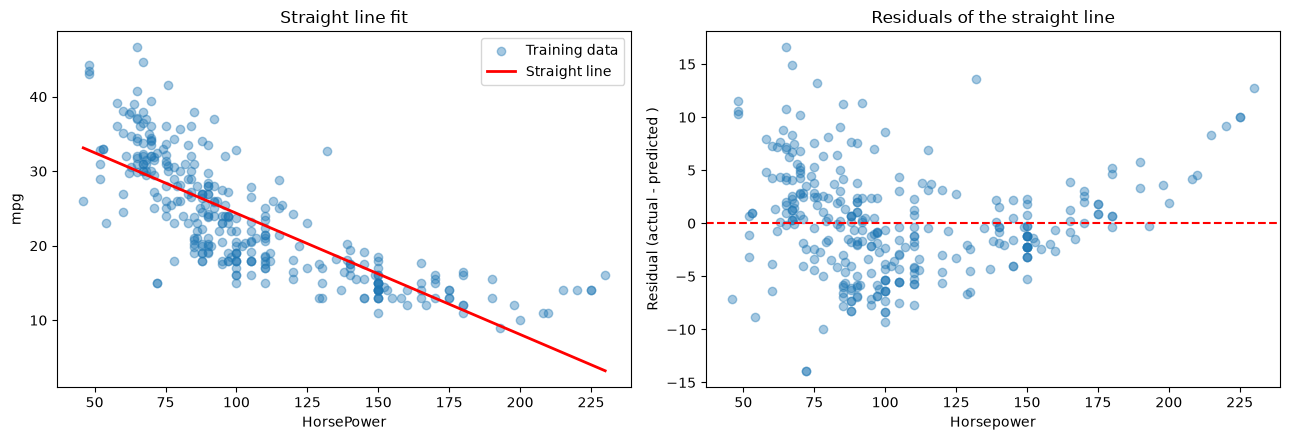

In [16]:
#  Two charts side by side
fig, ax = plt.subplots(1,2,figsize =(13, 4.5))

# Left: the data and the straight line
# We make 200evenly spaced horsepower values from smallest to largest, to draw a smooth line.
hp_range = pd.DataFrame({"horsepower": np.linspace(x["horsepower"].min(),x["horsepower"].max(),200)})
ax[0].scatter(x_train["horsepower"], y_train, alpha=0.4, label= "Training data")
ax[0].plot(hp_range["horsepower"], lin_model.predict(hp_range), color ="red", linewidth=2, label ="Straight line")
ax[0].set_xlabel("HorsePower")
ax[0].set_ylabel("mpg")
ax[0].set_title("Straight line fit")
ax[0].legend()


# Right: residuals = actual - predicted. For a good model they should be scattered randomly around 0.

residuals = y_train -lin_model.predict(x_train)
ax[1].scatter(x_train["horsepower"], residuals, alpha=0.4)
ax[1].axhline(0, color="red", linestyle ="--")
ax[1].set_xlabel("Horsepower")
ax[1].set_ylabel("Residual (actual - predicted )")
ax[1].set_title("Residuals of the straight line")

plt.tight_layout()
plt.show()


## 7. What PolynomialFeatures does
Before building the model, let's see what polynomial features does  to a few horsepower values.

In [18]:
# Take the first 3 horsepower values from the training data.
sample = x_train.head(3)

# degree =2 means: create x and x^2, include_bias = false means : don't add a column of 1s
# (LinearRegression already add its own intercept)

poly = PolynomialFeatures(degree = 2, include_bias=False)
sample_poly = poly.fit_transform(sample)

# Show the result as a table with readable column names
pd.DataFrame(sample_poly, columns =poly.get_feature_names_out(), index=sample.index)

,horsepower,horsepower^2
260,110.0,12100.0
184,92.0,8464.0
174,97.0,9409.0
